# Pipeline SC-WEAT dengan fastText Bahasa Indonesia

Notebook ini menggunakan data analisis KBJI dan model pretrained fastText Bahasa Indonesia Common Crawl + Wikipedia cc.id.300.bin. Skor positif berarti asosiasi relatif lebih dekat ke atribut laki-laki, skor negatif berarti relatif lebih dekat ke atribut perempuan. Ini bukan bukti diskriminasi atau kesesuaian pekerjaan.

## 1. Import, data, dan konfigurasi

In [1]:
import itertools
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics.pairwise import cosine_similarity
from statsmodels.stats.multitest import multipletests

try:
    import fasttext
except ImportError as exc:
    raise ImportError("Package fasttext belum terpasang. Jalankan pip install -r requirements.txt.") from exc

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
ROOT = Path.cwd()
DATA_DIR, OUTPUT_DIR, MODEL_DIR = ROOT / "data", ROOT / "outputs", ROOT / "models"
MODEL_PATH = MODEL_DIR / "cc.id.300.bin"
MODEL_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.bin.gz"
analysis_path = DATA_DIR / "test_kbji_profesional_analysis.csv"
assert analysis_path.exists()
df_analysis = pd.read_csv(analysis_path)
print("Python:", sys.version.split()[0], "| fasttext:", getattr(fasttext, "__version__", "unknown"))
print("Jabatan analisis:", len(df_analysis))

Python: 3.13.15 | fasttext: unknown
Jabatan analisis: 415


## 2. Model pretrained sebenarnya

Model binary tidak dibuat atau diganti otomatis. Jika belum tersedia, eksekusi berhenti dengan instruksi sumber resmi.

In [2]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model belum tersedia: {MODEL_PATH}. Unduh dari {MODEL_URL}, "
        "ekstrak sebagai cc.id.300.bin, lalu jalankan ulang notebook. Tidak ada model pengganti."
    )
if MODEL_PATH.stat().st_size < 100_000_000:
    raise RuntimeError("Ukuran model terlalu kecil; file mungkin belum diekstrak atau rusak.")
model = fasttext.load_model(str(MODEL_PATH))
model_dimension = model.get_dimension()
assert model_dimension == 300
print({"model": MODEL_PATH.name, "source": MODEL_URL, "size_bytes": MODEL_PATH.stat().st_size, "dimension": model_dimension})

{'model': 'cc.id.300.bin', 'source': 'https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.bin.gz', 'size_bytes': 7236808873, 'dimension': 300}


## 3. Lexical set istilah gender operasional

Daftar ini adalah lexical set operasional awal yang masih memerlukan validasi linguistik. Kategori berbeda dapat membawa konteks semantik tambahan.

In [3]:
gender_pairs = pd.DataFrame([
    (1, "laki-laki", "perempuan", "identitas"),
    (2, "pria", "wanita", "identitas"),
    (3, "ayah", "ibu", "kekerabatan"),
    (4, "suami", "istri", "kekerabatan"),
    (5, "putra", "putri", "kekerabatan"),
    (6, "pemuda", "pemudi", "usia/identitas"),
    (7, "cowok", "cewek", "informal"),
    (8, "jejaka", "gadis", "status/identitas"),
], columns=["pair_id", "male_term", "female_term", "category"])
gender_pairs["validation_status"] = "operasional; validasi linguistik lanjutan diperlukan"
gender_pairs["notes"] = "Kategori berbeda dapat membawa konteks semantik tambahan."
gender_pairs.to_csv(DATA_DIR / "test_istilah_gender.csv", index=False, encoding="utf-8")
display(gender_pairs)
assert gender_pairs.male_term.is_unique and gender_pairs.female_term.is_unique
assert not set(gender_pairs.male_term) & set(gender_pairs.female_term)

,pair_id,male_term,female_term,category,validation_status,notes
0,1,laki-laki,perempuan,identitas,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
1,2,pria,wanita,identitas,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
2,3,ayah,ibu,kekerabatan,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
3,4,suami,istri,kekerabatan,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
4,5,putra,putri,kekerabatan,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
5,6,pemuda,pemudi,usia/identitas,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
6,7,cowok,cewek,informal,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...
7,8,jejaka,gadis,status/identitas,operasional; validasi linguistik lanjutan dipe...,Kategori berbeda dapat membawa konteks semanti...


## 4. Tokenisasi dan representasi frasa

Nama jabatan multi-kata direpresentasikan dengan rata-rata vektor token lalu normalisasi L2. OOV tetap mendapat vektor subword fastText dan statusnya dicatat.

In [4]:
token_pattern = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*", flags=re.I)

def tokenize(text):
    return token_pattern.findall(str(text).lower())

def l2_normalize(vector):
    vector = np.asarray(vector, dtype=np.float32)
    norm = np.linalg.norm(vector)
    if not np.isfinite(norm) or norm == 0:
        raise ValueError("Vektor kosong atau tidak finite.")
    return vector / norm

def phrase_vector(text, ft_model):
    tokens = tokenize(text)
    return l2_normalize(np.vstack([ft_model.get_word_vector(t) for t in tokens]).mean(axis=0))

def embedding_audit(text, ft_model):
    tokens = tokenize(text)
    in_vocab = [ft_model.get_word_id(t) >= 0 for t in tokens]
    return {"tokens": tokens, "n_tokens": len(tokens), "n_in_vocabulary": int(sum(in_vocab)),
            "n_subword_oov": int(sum(not x for x in in_vocab)),
            "oov_ratio": float(sum(not x for x in in_vocab) / len(tokens)),
            "embedding_dimension": ft_model.get_dimension()}

gender_terms = gender_pairs.male_term.tolist() + gender_pairs.female_term.tolist()
term_audit = pd.DataFrame([embedding_audit(t, model) for t in gender_terms])
term_audit.insert(0, "term", gender_terms)
term_vectors = np.vstack([phrase_vector(t, model) for t in gender_terms])
occupation_audit = pd.DataFrame([embedding_audit(t, model) for t in df_analysis.occupation_text])
occupation_audit.insert(0, "occupation_code", df_analysis.occupation_code.to_numpy())
occupation_vectors = np.vstack([phrase_vector(t, model) for t in df_analysis.occupation_text])
occupation_audit["embedding_valid"] = np.isfinite(occupation_vectors).all(axis=1) & (np.linalg.norm(occupation_vectors, axis=1) > 0)
display(pd.DataFrame({"occupation_text": df_analysis.occupation_text.head(5),
                      "tokens": [tokenize(x) for x in df_analysis.occupation_text.head(5)]}))
display(term_audit)
display(occupation_audit.head())
print("shape occupation_vectors:", occupation_vectors.shape)

,occupation_text,tokens
0,ahli fisika,"[ahli, fisika]"
1,ahli fisika nuklir,"[ahli, fisika, nuklir]"
2,ahli fisika mekanika,"[ahli, fisika, mekanika]"
3,ahli fisika panas,"[ahli, fisika, panas]"
4,ahli fisika sinar,"[ahli, fisika, sinar]"


,term,tokens,n_tokens,n_in_vocabulary,n_subword_oov,oov_ratio,embedding_dimension
0,laki-laki,[laki-laki],1,1,0,0.0,300
1,pria,[pria],1,1,0,0.0,300
2,ayah,[ayah],1,1,0,0.0,300
3,suami,[suami],1,1,0,0.0,300
4,putra,[putra],1,1,0,0.0,300
5,pemuda,[pemuda],1,1,0,0.0,300
6,cowok,[cowok],1,1,0,0.0,300
7,jejaka,[jejaka],1,1,0,0.0,300
8,perempuan,[perempuan],1,1,0,0.0,300
9,wanita,[wanita],1,1,0,0.0,300


,occupation_code,tokens,n_tokens,n_in_vocabulary,n_subword_oov,oov_ratio,embedding_dimension,embedding_valid
0,2111.01,"[ahli, fisika]",2,2,0,0.0,300,True
1,2111.02,"[ahli, fisika, nuklir]",3,3,0,0.0,300,True
2,2111.03,"[ahli, fisika, mekanika]",3,3,0,0.0,300,True
3,2111.04,"[ahli, fisika, panas]",3,3,0,0.0,300,True
4,2111.05,"[ahli, fisika, sinar]",3,3,0,0.0,300,True


shape occupation_vectors: (415, 300)


## 5. Similarity dan SC-WEAT

Effect size memakai sample standard deviation ddof=1 dari 16 similarity atribut. Standar deviasi nol menjadi NaN agar kasus degenerat terlihat.

In [5]:
male_terms, female_terms = gender_pairs.male_term.tolist(), gender_pairs.female_term.tolist()
male_vectors = np.vstack([phrase_vector(t, model) for t in male_terms])
female_vectors = np.vstack([phrase_vector(t, model) for t in female_terms])

def calculate_sc_weat(occupation_vector, male_vectors, female_vectors):
    male_similarity = cosine_similarity(occupation_vector.reshape(1, -1), male_vectors).ravel()
    female_similarity = cosine_similarity(occupation_vector.reshape(1, -1), female_vectors).ravel()
    all_similarity = np.concatenate([male_similarity, female_similarity])
    difference = float(male_similarity.mean() - female_similarity.mean())
    sd = float(np.std(all_similarity, ddof=1))
    return {"male_similarity": male_similarity, "female_similarity": female_similarity,
            "mean_male_similarity": float(male_similarity.mean()), "mean_female_similarity": float(female_similarity.mean()),
            "association_difference": difference, "similarity_standard_deviation": sd,
            "scweat_effect_size": difference / sd if sd > 0 else np.nan}

rows, similarity_rows = [], []
for row, vector in zip(df_analysis.itertuples(index=False), occupation_vectors):
    scores = calculate_sc_weat(vector, male_vectors, female_vectors)
    effect = scores["scweat_effect_size"]
    direction = "positif" if effect > 0 else "negatif" if effect < 0 else "mendekati nol"
    rows.append({"occupation_code": row.occupation_code, "occupation_name_raw": row.occupation_name_raw,
                 "occupation_text": row.occupation_text, "submajor_group_code": row.submajor_group_code,
                 "submajor_group_name": row.submajor_group_name, "group_code": row.group_code,
                 "group_name": row.group_name, **{k: v for k, v in scores.items() if k not in {"male_similarity", "female_similarity"}},
                 "association_direction": direction})
    similarity_rows.append(np.r_[scores["male_similarity"], scores["female_similarity"]])
scweat_results = pd.DataFrame(rows)
all_gender_similarity = np.vstack(similarity_rows)
for i, term in enumerate(male_terms + female_terms):
    scweat_results["similarity_" + term.replace("-", "_")] = all_gender_similarity[:, i]
display(scweat_results.head())

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,similarity_cowok,similarity_jejaka,similarity_perempuan,similarity_wanita,similarity_ibu,similarity_istri,similarity_putri,similarity_pemudi,similarity_cewek,similarity_gadis
0,2111.01,Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.277370,0.269030,0.008341,...,0.281056,0.204403,0.278717,0.336805,0.295155,0.258918,0.220791,0.250648,0.246473,0.264731
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.268074,0.273548,-0.005474,...,0.270477,0.186724,0.304261,0.338438,0.287180,0.270728,0.223650,0.246123,0.246158,0.271848
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.254108,0.245780,0.008328,...,0.266454,0.202835,0.246588,0.315931,0.274067,0.224237,0.196392,0.209962,0.241302,0.257759
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.301160,0.300744,0.000416,...,0.305700,0.246030,0.314808,0.375900,0.318100,0.296434,0.224973,0.259147,0.292001,0.324585
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.296322,0.282230,0.014092,...,0.303354,0.246454,0.288678,0.352153,0.304000,0.267853,0.230308,0.248864,0.271176,0.294810


## 6. Exact two-sided permutation test dan FDR

In [6]:
combination_indices = np.array(list(itertools.combinations(range(16), 8)), dtype=np.int16)
assert len(combination_indices) == 12870
permutation_rows = []
for i, row in scweat_results.iterrows():
    similarities = all_gender_similarity[i]
    male_means = similarities[combination_indices].mean(axis=1)
    total_mean = similarities.mean()
    statistics = male_means - (16 * total_mean - 8 * male_means) / 8
    p = float((np.abs(statistics) >= abs(row.association_difference) - 1e-12).mean())
    permutation_rows.append({"occupation_code": row.occupation_code, "p_value": p,
                             "exact_partition_count": len(combination_indices), "test_sidedness": "two-sided"})
permutation_results = pd.DataFrame(permutation_rows)
rejected, adjusted, _, _ = multipletests(permutation_results.p_value, alpha=.05, method="fdr_bh")
permutation_results["adjusted_p_value"] = adjusted
permutation_results["significant_raw"] = permutation_results.p_value < .05
permutation_results["significant_fdr"] = rejected
scweat_results = scweat_results.merge(permutation_results, on="occupation_code", validate="one_to_one")
print("signifikan raw:", int(permutation_results.significant_raw.sum()),
      "| signifikan FDR:", int(permutation_results.significant_fdr.sum()))
display(permutation_results.nsmallest(10, "adjusted_p_value"))

signifikan raw: 0 | signifikan FDR: 0


,occupation_code,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr
0,2111.01,0.687646,12870,two-sided,0.999145,False,False
1,2111.02,0.804817,12870,two-sided,0.999145,False,False
2,2111.03,0.670940,12870,two-sided,0.999145,False,False
3,2111.04,0.986325,12870,two-sided,0.999145,False,False
4,2111.05,0.516861,12870,two-sided,0.999145,False,False
5,2111.06,0.692696,12870,two-sided,0.999145,False,False
6,2111.07,0.796270,12870,two-sided,0.999145,False,False
7,2111.08,0.811033,12870,two-sided,0.999145,False,False
8,2111.09,0.974359,12870,two-sided,0.999145,False,False
9,2111.10,0.759052,12870,two-sided,0.999145,False,False


## 7. Analisis pekerjaan dan visualisasi

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,similarity_putri,similarity_pemudi,similarity_cewek,similarity_gadis,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr
230,2320.02,Instruktur Tata Rias,instruktur tata rias,23,Profesional pendidikan,232,Pengajar Pendidikan Kejuruan,0.268557,0.302162,-0.033605,...,0.330607,0.269657,0.284349,0.285539,0.060062,12870,two-sided,0.999145,False,False
390,2653.02,Penari Balet,penari balet,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.291047,0.344046,-0.052999,...,0.329612,0.321086,0.326826,0.409604,0.081430,12870,two-sided,0.999145,False,False
162,2221.05,Perawat,perawat,22,Profesional kesehatan,222,Profesional Keperawatan dan Kebidanan,0.331399,0.382730,-0.051331,...,0.318908,0.307865,0.353160,0.406108,0.086791,12870,two-sided,0.999145,False,False
137,2166.10,Desainer Website,desainer website,21,Ahli ilmu pengetahuan dan teknik,216,"Arsitek, Perencana, Surveyor dan Desainer",0.226370,0.262434,-0.036064,...,0.265431,0.200101,0.257975,0.267944,0.106216,12870,two-sided,0.999145,False,False
248,2355.01,Guru Tari,guru tari,23,Profesional pendidikan,235,Profesional Bidang Pendidikan Lainnya,0.340893,0.381703,-0.040810,...,0.383370,0.358423,0.311188,0.364205,0.116939,12870,two-sided,0.999145,False,False
135,2166.08,Desainer Multimedia,desainer multimedia,21,Ahli ilmu pengetahuan dan teknik,216,"Arsitek, Perencana, Surveyor dan Desainer",0.251013,0.284155,-0.033142,...,0.269421,0.201116,0.300834,0.294238,0.130148,12870,two-sided,0.999145,False,False
292,2513.03,Pengembang Internet,pengembang internet,25,Profesional teknologi informasi dan komunikasi,251,Analis dan Pengembang Perangkat Lunak dan Apli...,0.261672,0.295041,-0.033370,...,0.228664,0.277272,0.286117,0.302753,0.134110,12870,two-sided,0.999145,False,False
164,2222.01,Bidan,bidan,22,Profesional kesehatan,222,Profesional Keperawatan dan Kebidanan,0.230423,0.292101,-0.061677,...,0.246913,0.239350,0.155621,0.251842,0.153069,12870,two-sided,0.999145,False,False
163,2221.06,Perawat Anastesi,perawat anastesi,22,Profesional kesehatan,222,Profesional Keperawatan dan Kebidanan,0.261542,0.309276,-0.047734,...,0.239772,0.196633,0.293218,0.315410,0.167754,12870,two-sided,0.999145,False,False
287,2512.02,Desainer Software,desainer software,25,Profesional teknologi informasi dan komunikasi,251,Analis dan Pengembang Perangkat Lunak dan Apli...,0.246614,0.276951,-0.030337,...,0.275425,0.230892,0.283888,0.316551,0.170707,12870,two-sided,0.999145,False,False


,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,similarity_putri,similarity_pemudi,similarity_cewek,similarity_gadis,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr
384,2652.02,Komposer,komposer,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.263948,0.229909,0.034039,...,0.170172,0.253022,0.186261,0.246578,0.079254,12870,two-sided,0.999145,False,False
409,2659.03,Badut,badut,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.195635,0.174448,0.021187,...,0.182334,0.158035,0.193972,0.194035,0.195260,12870,two-sided,0.999145,False,False
400,2655.01,Aktor,aktor,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.364733,0.324142,0.040591,...,0.297947,0.238909,0.337715,0.372243,0.205750,12870,two-sided,0.999145,False,False
10,2112.01,Ahli Meteorologi (Umum),ahli meteorologi,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.254620,0.227552,0.027068,...,0.171010,0.242091,0.191604,0.216798,0.275680,12870,two-sided,0.999145,False,False
387,2652.05,Orchestrator,orchestrator,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.151546,0.127285,0.024261,...,0.114587,0.118103,0.089868,0.080547,0.271018,12870,two-sided,0.999145,False,False
378,2651.01,Kartunis,kartunis,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.228587,0.211156,0.017431,...,0.185369,0.180789,0.166430,0.200553,0.293162,12870,two-sided,0.999145,False,False
398,2654.06,Pengarah Teknis,pengarah teknis,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.232941,0.212930,0.020012,...,0.157086,0.173508,0.183067,0.230389,0.339627,12870,two-sided,0.999145,False,False
22,2114.04,Ahli Geofisika (Umum),ahli geofisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.272689,0.251956,0.020734,...,0.178470,0.289691,0.256452,0.248108,0.365812,12870,two-sided,0.999145,False,False
44,2132.01,Ahli Agronomi,ahli agronomi,21,Ahli ilmu pengetahuan dan teknik,213,Ahli Ilmu Pengetahuan Hayati,0.255089,0.238528,0.016561,...,0.212507,0.234516,0.164124,0.216426,0.476224,12870,two-sided,0.999145,False,False
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.296322,0.282230,0.014092,...,0.230308,0.248864,0.271176,0.294810,0.516861,12870,two-sided,0.999145,False,False


,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,similarity_putri,similarity_pemudi,similarity_cewek,similarity_gadis,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr
25,2120.02,Ahli Matematika Terapan,ahli matematika terapan,21,Ahli ilmu pengetahuan dan teknik,212,"Ahli Matematika, Aktuaria Dan Statistika",0.272889,0.272866,0.000023,...,0.194920,0.245486,0.242170,0.246906,0.999145,12870,two-sided,0.999145,False,False
334,2633.03,Ahli Politik,ahli politik,26,"Profesional hukum, sosial dan budaya",263,Profesional Sosial dan Keagamaan,0.306441,0.306362,0.000079,...,0.226724,0.294101,0.225776,0.263371,0.998757,12870,two-sided,0.999145,False,False
410,2659.04,Ahli Hipnotis,ahli hipnotis,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.255722,0.255642,0.000080,...,0.160271,0.241507,0.232519,0.259293,0.997980,12870,two-sided,0.999145,False,False
309,2611.01,Pengacara,pengacara,26,"Profesional hukum, sosial dan budaya",261,Profesional Hukum,0.297544,0.297432,0.000113,...,0.271973,0.236914,0.183397,0.340334,0.998057,12870,two-sided,0.999145,False,False
131,2166.04,Ilustrator Teknik,ilustrator teknik,21,Ahli ilmu pengetahuan dan teknik,216,"Arsitek, Perencana, Surveyor dan Desainer",0.252060,0.252117,-0.000057,...,0.212816,0.191569,0.278451,0.273139,0.996814,12870,two-sided,0.999145,False,False
46,2132.03,Ahli Penelitian Tanah,ahli penelitian tanah,21,Ahli ilmu pengetahuan dan teknik,213,Ahli Ilmu Pengetahuan Hayati,0.330869,0.330977,-0.000109,...,0.254543,0.314411,0.267289,0.315001,0.996581,12870,two-sided,0.999145,False,False
140,2212.01,Dokter Spesialis Anestesi,dokter spesialis anestesi,22,Profesional kesehatan,221,Dokter Medis,0.294218,0.294339,-0.000121,...,0.260731,0.194545,0.248549,0.281251,0.997436,12870,two-sided,0.999145,False,False
407,2659.01,Pemain Akrobat,pemain akrobat,26,"Profesional hukum, sosial dan budaya",265,Seniman Kreatif dan Pertunjukan,0.303086,0.302969,0.000117,...,0.265543,0.248475,0.319764,0.351604,0.996581,12870,two-sided,0.999145,False,False
45,2132.02,Ahli Kehutanan,ahli kehutanan,21,Ahli ilmu pengetahuan dan teknik,213,Ahli Ilmu Pengetahuan Hayati,0.261164,0.261379,-0.000215,...,0.210717,0.282466,0.176801,0.246726,0.995338,12870,two-sided,0.999145,False,False
262,2413.02,Konsultan Investasi,konsultan investasi,24,Profesional bisnis dan administrasi,241,Profesional Keuangan,0.247706,0.248000,-0.000293,...,0.193191,0.176911,0.239639,0.213042,0.990287,12870,two-sided,0.999145,False,False


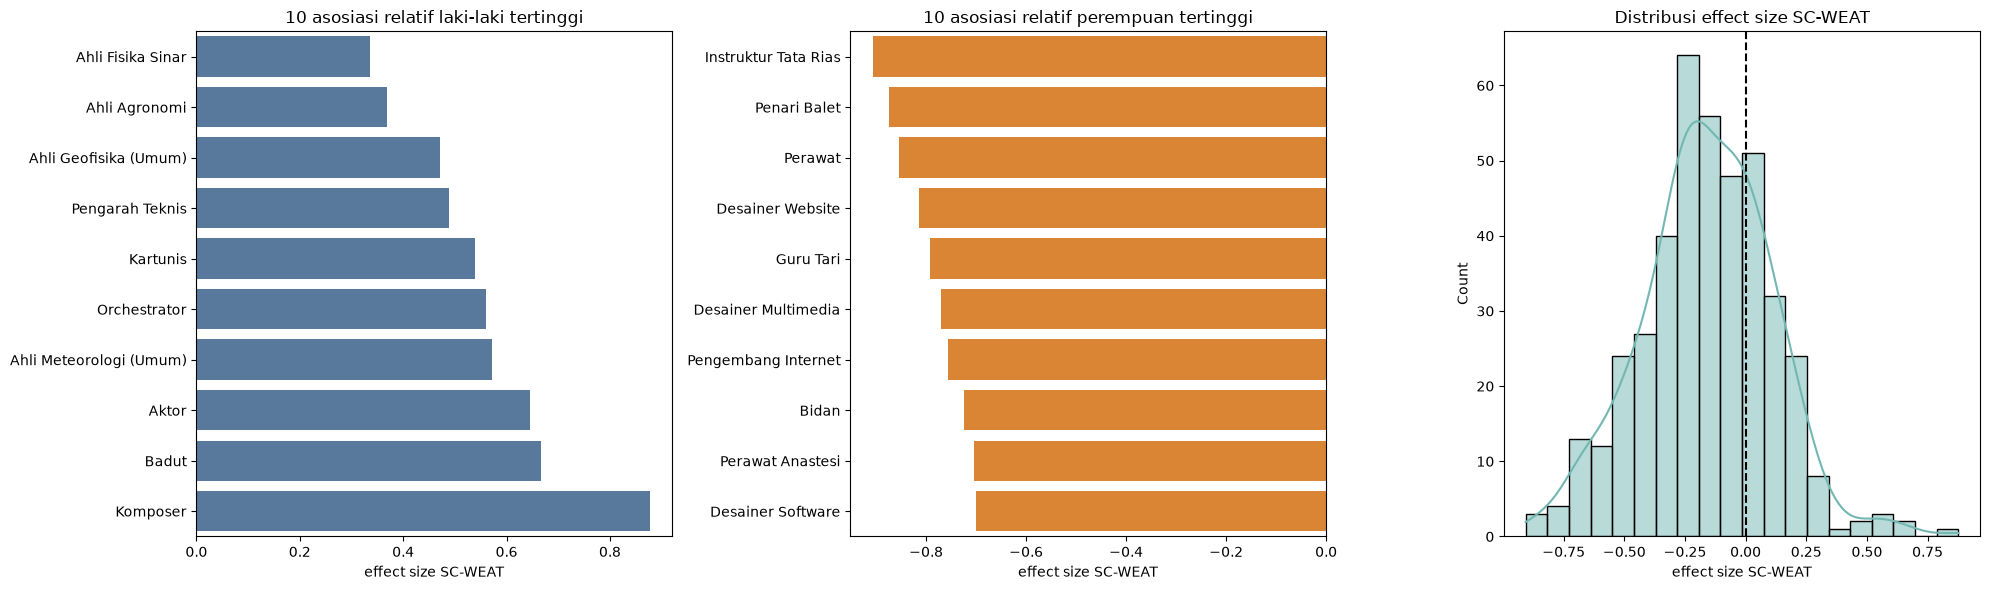

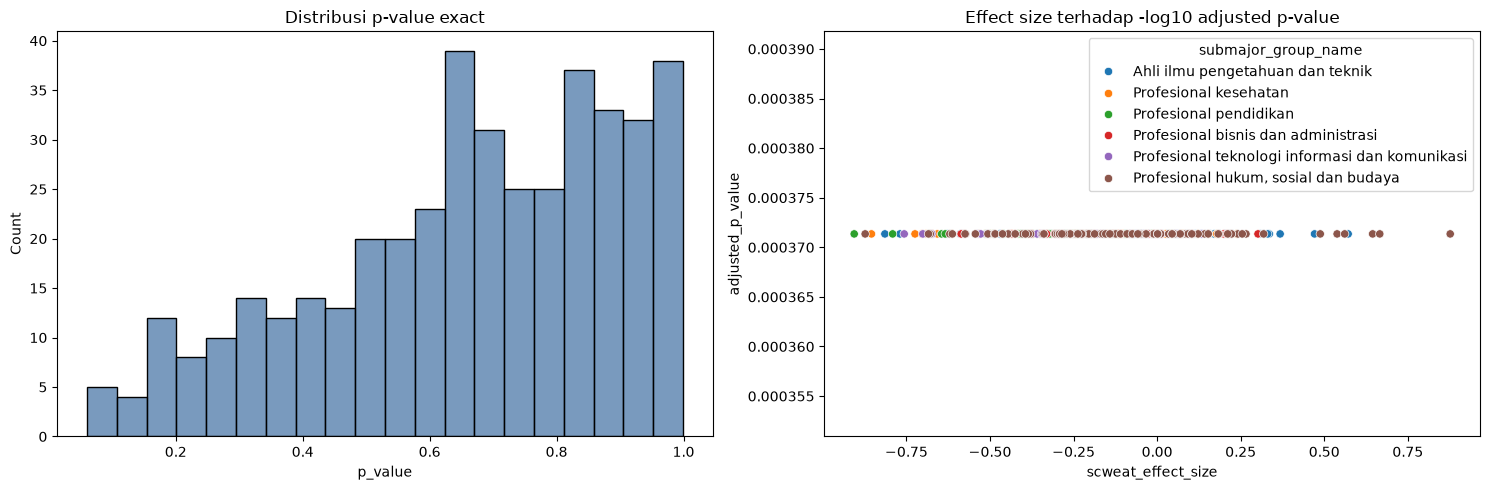

In [7]:
display(scweat_results.nsmallest(10, "scweat_effect_size"))
display(scweat_results.nlargest(10, "scweat_effect_size"))
display(scweat_results.iloc[np.argsort(np.abs(scweat_results.scweat_effect_size))[:10]])
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.barplot(data=scweat_results.nlargest(10, "scweat_effect_size").sort_values("scweat_effect_size"),
            x="scweat_effect_size", y="occupation_name_raw", color="#4C78A8", ax=axes[0])
sns.barplot(data=scweat_results.nsmallest(10, "scweat_effect_size").sort_values("scweat_effect_size"),
            x="scweat_effect_size", y="occupation_name_raw", color="#F58518", ax=axes[1])
sns.histplot(scweat_results.scweat_effect_size, kde=True, color="#72B7B2", ax=axes[2])
axes[0].set(title="10 asosiasi relatif laki-laki tertinggi", xlabel="effect size SC-WEAT", ylabel="")
axes[1].set(title="10 asosiasi relatif perempuan tertinggi", xlabel="effect size SC-WEAT", ylabel="")
axes[2].axvline(0, color="black", linestyle="--"); axes[2].set(title="Distribusi effect size SC-WEAT", xlabel="effect size SC-WEAT")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(permutation_results.p_value, bins=20, color="#4C78A8", ax=axes[0])
sns.scatterplot(data=scweat_results, x="scweat_effect_size",
                y=-np.log10(scweat_results.adjusted_p_value.clip(lower=1e-300)),
                hue="submajor_group_name", ax=axes[1])
axes[0].set(title="Distribusi p-value exact"); axes[1].set(title="Effect size terhadap -log10 adjusted p-value")
plt.tight_layout(); plt.show()

## 8. Leave-one-pair-out

,excluded_pair_id,excluded_terms,pearson_correlation,spearman_rank_correlation,mean_absolute_change,direction_preserved_proportion,sign_change_count,min_effect_size_leave_one_out,max_effect_size_leave_one_out
0,1,"laki-laki, perempuan",0.975462,0.970112,0.059980,0.915663,35,-0.889893,0.951176
1,2,"pria, wanita",0.974669,0.974200,0.063278,0.915663,35,-1.018021,0.875843
2,3,"ayah, ibu",0.951683,0.946477,0.064535,0.915663,35,-0.959684,0.654423
3,4,"suami, istri",0.976442,0.974984,0.045549,0.939759,25,-0.988602,1.119902
4,5,"putra, putri",0.971217,0.971531,0.056695,0.942169,24,-0.887963,0.707263
5,6,"pemuda, pemudi",0.940704,0.944097,0.255127,0.802410,82,-1.201375,0.895415
6,7,"cowok, cewek",0.988004,0.988743,0.049837,0.937349,26,-0.906794,0.846279
7,8,"jejaka, gadis",0.932252,0.928331,0.226635,0.640964,149,-0.862995,1.054529


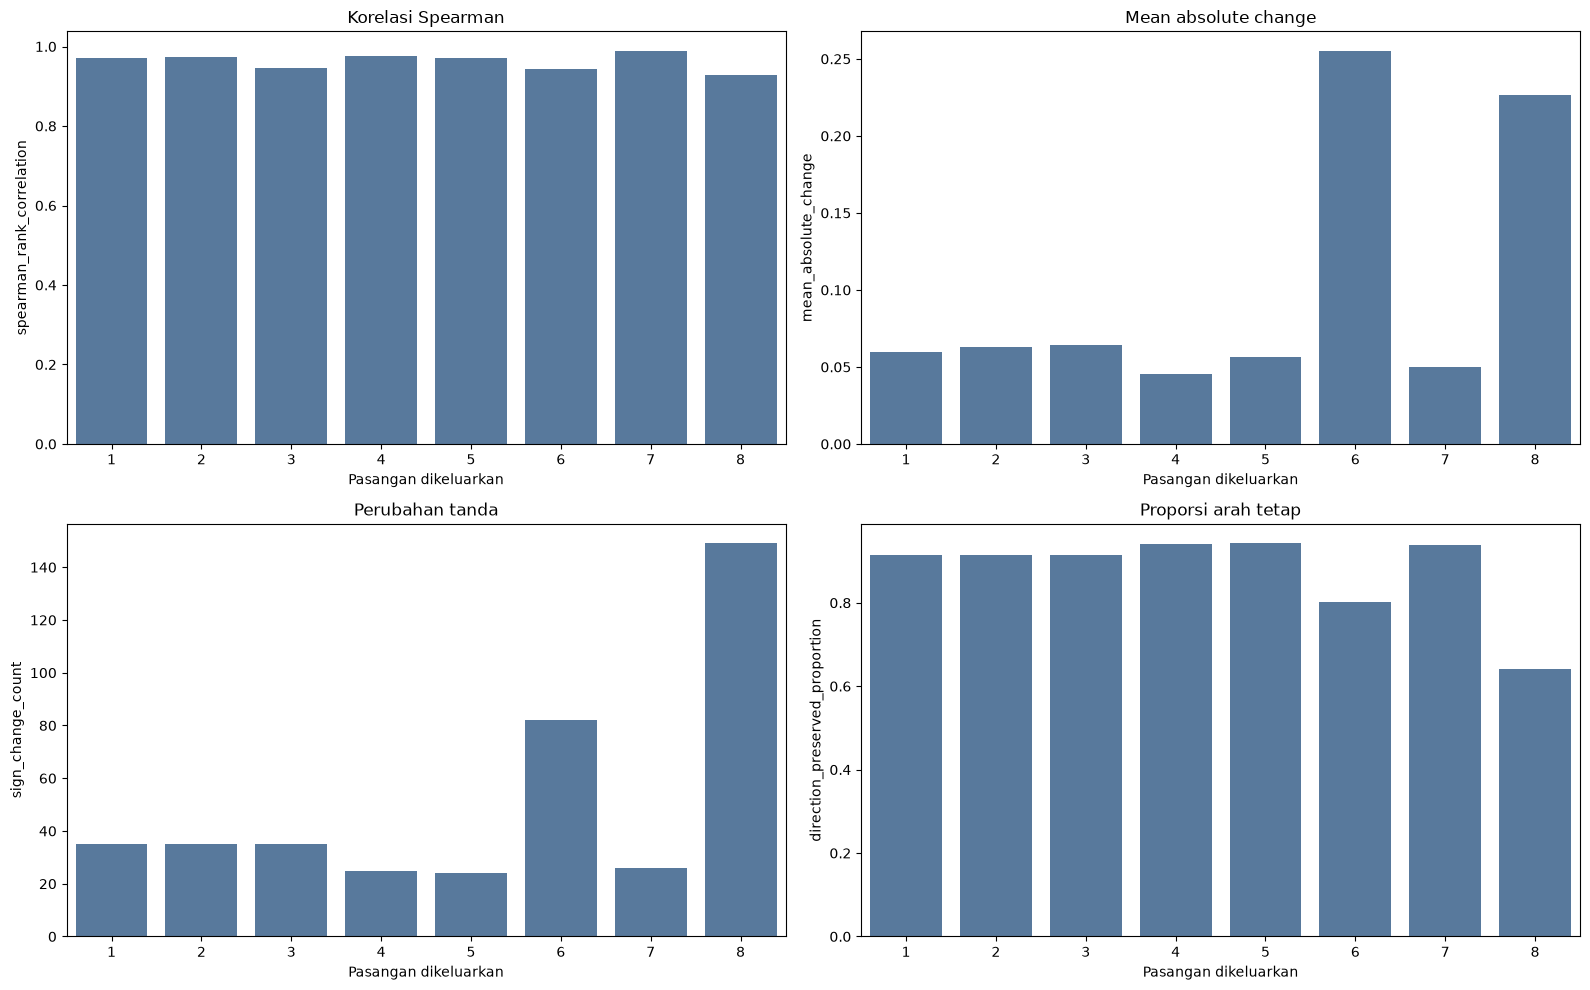

In [8]:
baseline = scweat_results.set_index("occupation_code").scweat_effect_size
sensitivity_rows, sensitivity_effects = [], {}
for pair_id in gender_pairs.pair_id:
    keep = gender_pairs.pair_id != pair_id
    keep_male = np.vstack([phrase_vector(t, model) for t in gender_pairs.loc[keep, "male_term"]])
    keep_female = np.vstack([phrase_vector(t, model) for t in gender_pairs.loc[keep, "female_term"]])
    effects = pd.Series([calculate_sc_weat(v, keep_male, keep_female)["scweat_effect_size"] for v in occupation_vectors],
                        index=df_analysis.occupation_code)
    sensitivity_effects[int(pair_id)] = effects
    rho, _ = spearmanr(baseline, effects)
    pearson, _ = pearsonr(baseline, effects)
    same = np.sign(baseline) == np.sign(effects)
    pair = gender_pairs[gender_pairs.pair_id == pair_id].iloc[0]
    sensitivity_rows.append({"excluded_pair_id": pair_id, "excluded_terms": f"{pair.male_term}, {pair.female_term}",
                             "pearson_correlation": pearson, "spearman_rank_correlation": rho,
                             "mean_absolute_change": float(np.abs(baseline - effects).mean()),
                             "direction_preserved_proportion": float(same.mean()),
                             "sign_change_count": int((~same).sum()),
                             "min_effect_size_leave_one_out": float(effects.min()),
                             "max_effect_size_leave_one_out": float(effects.max())})
sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, y, title in zip(axes.ravel(), ["spearman_rank_correlation", "mean_absolute_change", "sign_change_count", "direction_preserved_proportion"],
                        ["Korelasi Spearman", "Mean absolute change", "Perubahan tanda", "Proporsi arah tetap"]):
    sns.barplot(data=sensitivity_results, x="excluded_pair_id", y=y, color="#4C78A8", ax=ax)
    ax.set(title=title, xlabel="Pasangan dikeluarkan", ylabel=y)
plt.tight_layout(); plt.show()

## 9. Ringkasan kelompok dan audit embedding

,submajor_group_code,submajor_group_name,occupation_count,mean_effect_size,median_effect_size,std_effect_size,minimum_effect_size,maximum_effect_size,positive_count,negative_count,significant_raw_count,significant_fdr_count,median_oov_ratio,iqr_effect_size,median_sign_agreement_leave_one_pair_out
0,21,Ahli ilmu pengetahuan dan teknik,138,-0.082250,-0.047292,0.242135,-0.814373,0.571464,50,88,0,0,0.0,0.296325,0.915663
1,22,Profesional kesehatan,74,-0.235342,-0.212349,0.248457,-0.854570,0.237688,13,61,0,0,0.0,0.325077,0.915663
2,23,Profesional pendidikan,42,-0.331064,-0.310923,0.202168,-0.906219,0.043403,2,40,0,0,0.0,0.179916,0.915663
3,24,Profesional bisnis dan administrasi,29,-0.151925,-0.116490,0.230783,-0.586172,0.301764,7,22,0,0,0.0,0.331097,0.915663
4,25,Profesional teknologi informasi dan komunikasi,26,-0.260260,-0.185226,0.247994,-0.756594,0.133476,3,23,0,0,0.0,0.392331,0.915663
5,26,"Profesional hukum, sosial dan budaya",106,-0.116119,-0.160693,0.304231,-0.873416,0.876769,37,69,0,0,0.0,0.357871,0.915663


,group_code,group_name,occupation_count,mean_effect_size,median_effect_size,std_effect_size,minimum_effect_size,maximum_effect_size,positive_count,negative_count,significant_raw_count,significant_fdr_count,median_oov_ratio,iqr_effect_size,median_sign_agreement_leave_one_pair_out
0,211,Ahli Fisika dan Ilmu Bumi,24,0.141593,0.127857,0.164203,-0.131233,0.571464,20,4,0,0,0.0,0.165418,0.915663
1,212,"Ahli Matematika, Aktuaria Dan Statistika",7,0.049003,0.007174,0.085917,-0.022046,0.224695,5,2,0,0,0.0,0.074300,0.915663
2,213,Ahli Ilmu Pengetahuan Hayati,25,-0.031302,-0.020422,0.206808,-0.407730,0.368014,9,16,0,0,0.0,0.329068,0.915663
3,214,Ahli Teknik (Selain Ahli Teknologi Elektro),45,-0.147114,-0.157908,0.132050,-0.398364,0.180111,6,39,0,0,0.0,0.177524,0.915663
4,215,Ahli Teknik Teknologi Elektro,10,-0.008789,-0.034025,0.136048,-0.212763,0.308662,3,7,0,0,0.0,0.077065,0.915663
5,216,"Arsitek, Perencana, Surveyor dan Desainer",27,-0.281527,-0.239060,0.322488,-0.814373,0.330683,7,20,0,0,0.0,0.572503,0.915663
6,221,Dokter Medis,20,-0.078451,-0.107523,0.099786,-0.245576,0.154293,3,17,0,0,0.0,0.106748,0.915663
7,222,Profesional Keperawatan dan Kebidanan,7,-0.613910,-0.671142,0.169255,-0.854570,-0.393961,0,7,0,0,0.0,0.239512,0.915663
8,223,Profesional Pengobatan Tradisional dan Komplem...,6,-0.264078,-0.351932,0.302016,-0.613372,0.121765,2,4,0,0,0.0,0.447306,0.915663
9,224,Praktisi Paramedis,3,-0.138269,-0.217943,0.343129,-0.434552,0.237688,1,2,0,0,0.0,0.336120,0.915663


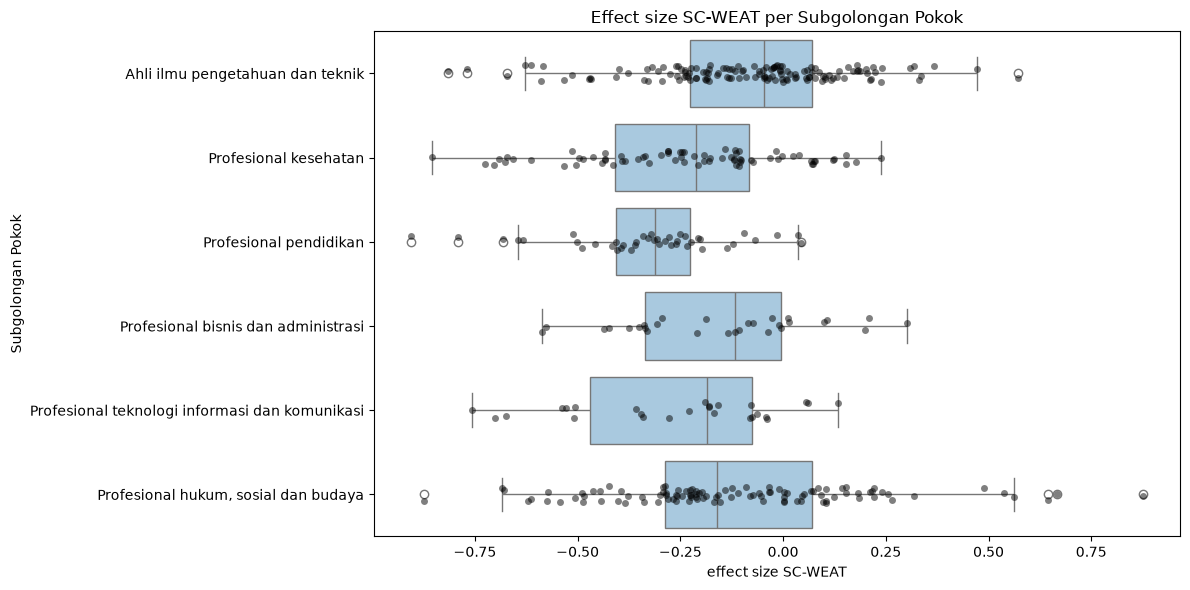

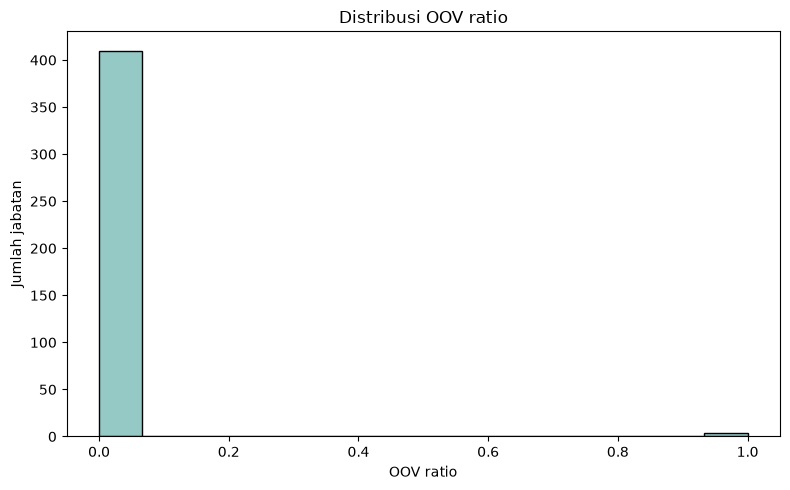

In [9]:
occupation_audit = occupation_audit.set_index("occupation_code").loc[scweat_results.occupation_code].reset_index()
scweat_results["oov_ratio"] = occupation_audit.oov_ratio.to_numpy()
sign_agreement_median = pd.DataFrame(sensitivity_effects).apply(lambda x: np.mean(np.sign(baseline) == np.sign(x))).median()

def summarize(grouped):
    out = grouped.agg(occupation_count=("occupation_code", "count"), mean_effect_size=("scweat_effect_size", "mean"),
        median_effect_size=("scweat_effect_size", "median"), std_effect_size=("scweat_effect_size", "std"),
        minimum_effect_size=("scweat_effect_size", "min"), maximum_effect_size=("scweat_effect_size", "max"),
        positive_count=("scweat_effect_size", lambda x: int((x > 0).sum())),
        negative_count=("scweat_effect_size", lambda x: int((x < 0).sum())),
        significant_raw_count=("significant_raw", "sum"), significant_fdr_count=("significant_fdr", "sum"),
        median_oov_ratio=("oov_ratio", "median")).reset_index()
    out["iqr_effect_size"] = grouped.scweat_effect_size.quantile(.75).to_numpy() - grouped.scweat_effect_size.quantile(.25).to_numpy()
    out["median_sign_agreement_leave_one_pair_out"] = sign_agreement_median
    return out

summary_submajor = summarize(scweat_results.groupby(["submajor_group_code", "submajor_group_name"], sort=True))
summary_group = summarize(scweat_results.groupby(["group_code", "group_name"], sort=True))
display(summary_submajor); display(summary_group)
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=scweat_results, x="scweat_effect_size", y="submajor_group_name", color="#A0CBE8", ax=ax)
sns.stripplot(data=scweat_results, x="scweat_effect_size", y="submajor_group_name", color="black", alpha=.5, ax=ax)
ax.set(title="Effect size SC-WEAT per Subgolongan Pokok", xlabel="effect size SC-WEAT", ylabel="Subgolongan Pokok")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(occupation_audit.oov_ratio, bins=15, color="#72B7B2", ax=ax)
ax.set(title="Distribusi OOV ratio", xlabel="OOV ratio", ylabel="Jumlah jabatan")
plt.tight_layout(); plt.show()

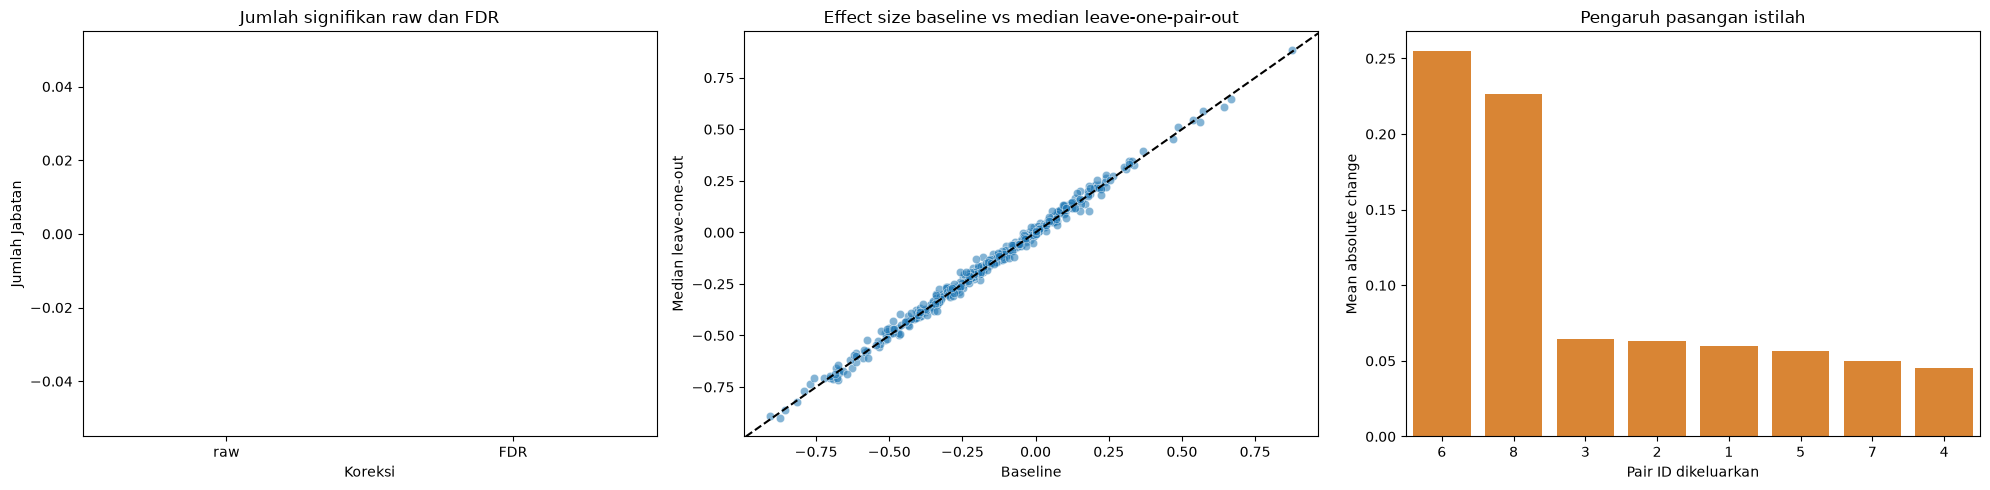

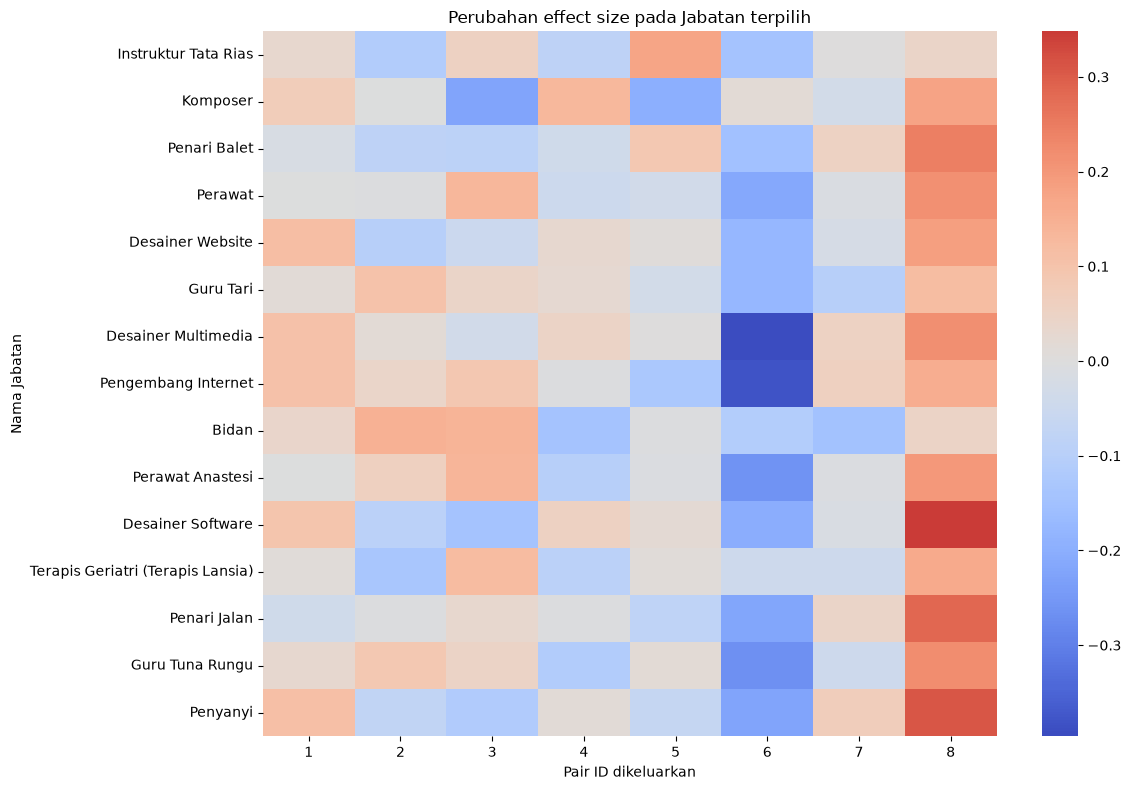

In [10]:

## Visualisasi tambahan quality control

# Panel ini membandingkan signifikansi sebelum dan sesudah FDR, kestabilan effect size, dan perubahan akibat tiap pasangan istilah.

significant_counts = pd.DataFrame({
    "status": ["raw", "FDR"],
    "count": [int(permutation_results.significant_raw.sum()), int(permutation_results.significant_fdr.sum())],
})
loo_frame = pd.DataFrame(sensitivity_effects)
median_loo = loo_frame.median(axis=1)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.barplot(data=significant_counts, x="status", y="count", color="#4C78A8", ax=axes[0])
sns.scatterplot(x=baseline, y=median_loo, alpha=.55, ax=axes[1])
axes[1].axline((0, 0), slope=1, color="black", linestyle="--")
pair_influence = sensitivity_results.set_index("excluded_pair_id")["mean_absolute_change"].sort_values(ascending=False)
sns.barplot(x=pair_influence.index.astype(str), y=pair_influence.values, color="#F58518", ax=axes[2])
axes[0].set(title="Jumlah signifikan raw dan FDR", xlabel="Koreksi", ylabel="Jumlah Jabatan")
axes[1].set(title="Effect size baseline vs median leave-one-pair-out", xlabel="Baseline", ylabel="Median leave-one-out")
axes[2].set(title="Pengaruh pasangan istilah", xlabel="Pair ID dikeluarkan", ylabel="Mean absolute change")
plt.tight_layout(); plt.show()

selected_codes = scweat_results.reindex(scweat_results.scweat_effect_size.abs().nlargest(15).index).occupation_code
change_matrix = pd.DataFrame({str(k): sensitivity_effects[k].loc[selected_codes] - baseline.loc[selected_codes] for k in sensitivity_effects})
change_matrix.index = scweat_results.set_index("occupation_code").loc[selected_codes].occupation_name_raw
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(change_matrix, center=0, cmap="coolwarm", ax=ax)
ax.set(title="Perubahan effect size pada Jabatan terpilih", xlabel="Pair ID dikeluarkan", ylabel="Nama Jabatan")
plt.tight_layout(); plt.show()


## 10. Menyimpan output tabular

In [11]:
OUTPUT_DIR.mkdir(exist_ok=True)
scweat_results.to_csv(OUTPUT_DIR / "test_hasil_scweat.csv", index=False, encoding="utf-8")
permutation_results.to_csv(OUTPUT_DIR / "test_hasil_permutasi.csv", index=False, encoding="utf-8")
sensitivity_results.to_csv(OUTPUT_DIR / "test_hasil_sensitivitas.csv", index=False, encoding="utf-8")
summary_submajor.to_csv(OUTPUT_DIR / "test_ringkasan_subgolongan_pokok.csv", index=False, encoding="utf-8")
summary_group.to_csv(OUTPUT_DIR / "test_ringkasan_golongan.csv", index=False, encoding="utf-8")
occupation_audit.to_csv(OUTPUT_DIR / "test_audit_embedding.csv", index=False, encoding="utf-8")
display(pd.read_csv(OUTPUT_DIR / "test_hasil_scweat.csv").head())

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,group_code,group_name,mean_male_similarity,mean_female_similarity,association_difference,...,similarity_pemudi,similarity_cewek,similarity_gadis,p_value,exact_partition_count,test_sidedness,adjusted_p_value,significant_raw,significant_fdr,oov_ratio
0,2111.01,Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.277370,0.269030,0.008341,...,0.250648,0.246473,0.264731,0.687646,12870,two-sided,0.999145,False,False,0.0
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.268074,0.273548,-0.005474,...,0.246123,0.246159,0.271848,0.804817,12870,two-sided,0.999145,False,False,0.0
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.254108,0.245780,0.008328,...,0.209962,0.241302,0.257759,0.670940,12870,two-sided,0.999145,False,False,0.0
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.301160,0.300744,0.000416,...,0.259147,0.292001,0.324585,0.986325,12870,two-sided,0.999145,False,False,0.0
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,0.296322,0.282230,0.014092,...,0.248864,0.271176,0.294810,0.516861,12870,two-sided,0.999145,False,False,0.0


## 11. Quality control final

## 12. Batas interpretasi

Semua angka berasal dari eksekusi kode. Hasil hanya berlaku untuk cc.id.300.bin dan lexical set operasional ini. Hasil tidak membuktikan komposisi gender tenaga kerja, diskriminasi perekrutan, kecocokan pekerjaan untuk gender tertentu, atau fairness aplikasi downstream.

In [12]:
shuffled = gender_pairs.sample(frac=1, random_state=RANDOM_SEED)
sh_male = np.vstack([phrase_vector(t, model) for t in shuffled.male_term])
sh_female = np.vstack([phrase_vector(t, model) for t in shuffled.female_term])
shuffled_effects = [calculate_sc_weat(v, sh_male, sh_female)["scweat_effect_size"] for v in occupation_vectors]
finite_vectors = bool(np.isfinite(occupation_vectors).all() and (np.linalg.norm(occupation_vectors, axis=1) > 0).all())
valid_cosine = bool((all_gender_similarity >= -1 - 1e-6).all() and (all_gender_similarity <= 1 + 1e-6).all())
valid_p = bool(permutation_results[["p_value", "adjusted_p_value"]].apply(lambda x: x.between(0, 1).all()).all())
checks = [
    ("model pretrained binary tersedia", True, MODEL_PATH.exists(), MODEL_PATH.name),
    ("dimensi embedding", 300, model_dimension, "fastText"),
    ("occupation_code unik", True, df_analysis.occupation_code.is_unique, "data analisis"),
    ("vektor finite dan bukan nol", True, finite_vectors, "frasa rata-rata token"),
    ("cosine valid", True, valid_cosine, "rentang [-1, 1]"),
    ("exact partitions", 12870, len(combination_indices), "C(16,8)"),
    ("p-value valid", True, valid_p, "two-sided + FDR BH"),
    ("invariansi urutan istilah", True, bool(np.allclose(np.sort(shuffled_effects), np.sort(scweat_results.scweat_effect_size), rtol=1e-5, atol=1e-5, equal_nan=True)), "effect size"),
    ("leave-one-pair-out", 8, len(sensitivity_results), "satu iterasi per pasangan"),
    ("jumlah output sama dengan jabatan", len(df_analysis), len(scweat_results), "hasil utama"),
]
validation_pipeline = pd.DataFrame([{"check_name": n, "expected": e, "observed": o, "status": "PASS" if o == e else "FAIL", "notes": note}
                                    for n, e, o, note in checks])
validation_pipeline.to_csv(OUTPUT_DIR / "test_validasi_pipeline.csv", index=False, encoding="utf-8")
display(validation_pipeline)
assert (validation_pipeline.status == "PASS").all()

,check_name,expected,observed,status,notes
0,model pretrained binary tersedia,True,True,PASS,cc.id.300.bin
1,dimensi embedding,300,300,PASS,fastText
2,occupation_code unik,True,True,PASS,data analisis
3,vektor finite dan bukan nol,True,True,PASS,frasa rata-rata token
4,cosine valid,True,True,PASS,"rentang [-1, 1]"
5,exact partitions,12870,12870,PASS,"C(16,8)"
6,p-value valid,True,True,PASS,two-sided + FDR BH
7,invariansi urutan istilah,True,True,PASS,effect size
8,leave-one-pair-out,8,8,PASS,satu iterasi per pasangan
9,jumlah output sama dengan jabatan,415,415,PASS,hasil utama
